<a href="https://colab.research.google.com/github/AshaMomo/AshaMomo/blob/main/mental_health.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/train.txt', sep =';' , header = None , names =['text', 'emotion'])

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df.head()

,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:
df.isnull().sum()

,0
text,0
emotion,0


In [ ]:
df['emotion'].unique()

array(['sadness', 'anger', 'love', 'surprise', 'fear', 'joy'],
      dtype=object)

In [ ]:
unique_emotions = df['emotion'].unique()
emotion_numbers = {}
i = 0
for emo in unique_emotions:
  emotion_numbers[emo] = i
  i += 1

df['emotion'] = df['emotion'].map(emotion_numbers)

**converting in numbers**

In [ ]:
df

,text,emotion
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,1
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,1
...,...,...
15995,i just had a very brief time in the beanbag an...,0
15996,i am now turning and i feel pathetic that i am...,0
15997,i feel strong and good overall,5
15998,i feel like this was such a rude comment and i...,1


**lower case**


In [ ]:
df['text'] = df['text'].apply(lambda x: x.lower())

text cleaning

In [ ]:
import string
def remove_punc(txt) :
  return txt.translate(str.maketrans('','',string.punctuation))

In [ ]:
df['text'] = df['text'].apply(remove_punc)

In [ ]:
def remove_numbers(txt):
    new = ""

    for i in txt:
        if not i.isdigit():
            new = new + i

    return new
    df['text'] = df['text'].apply(remove_numbers)



In [ ]:
def remove_emojis(txt) :
  new = ""
  for i in txt :
   if not i.isascii():
       new = new + i
  return new
  df['text'] = df['text'].apply(remove_emojis)

In [ ]:
import nltk

In [ ]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

In [ ]:
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
stop_words = set(stopwords.words('english'))
stop_words

{'a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 "he's",
 'her',
 'here',
 'hers',
 'herself',
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 "i'll",
 "i'm",
 "i've",
 'if',
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [ ]:
stop_words = set(stopwords.words('english'))

In [ ]:
def remove(txt):
    words = txt.split()
    cleaned = []

    for i in words:
        if i not in stop_words:
            cleaned.append(i)

    return '  '.join(cleaned)

In [ ]:
df['text']= df['text'].apply(remove)

In [ ]:
df.loc[1]['text']

'go  feeling  hopeless  damned  hopeful  around  someone  cares  awake'

split text

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( df['text'], df['emotion'], test_size=0.20,
random_state=42)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer , CountVectorizer

In [ ]:
bow_vectorizer = CountVectorizer()

In [ ]:
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

In [ ]:
nb_model = MultinomialNB()

In [ ]:
nb_model.fit(X_train_bow, y_train)

MultinomialNB()

In [ ]:
pred_nb = nb_model.predict(X_test_bow)

In [ ]:
print(accuracy_score(y_test, pred_nb))

0.768125


In [ ]:
tfidf_vectorizer = TfidfVectorizer()

In [ ]:
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [ ]:
nb2_model = MultinomialNB()
nb2_model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [ ]:
y_pred = nb2_model.predict(X_test_tfidf)

In [ ]:
print(accuracy_score(y_test, y_pred))

0.6609375


In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
logistic_model = LogisticRegression(max_iter=1000)

In [ ]:
logistic_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
log_pred = logistic_model.predict(X_test_tfidf)

In [ ]:
logistic_accuracy = accuracy_score(y_test, log_pred)
print(logistic_accuracy)

0.8628125


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Linear SVM model
svm_model = LinearSVC()

# Train
svm_model.fit(X_train_tfidf, y_train)

# Prediction
y_pred_svm = svm_model.predict(X_test_tfidf)

# Accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("Linear SVM Accuracy:", svm_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))

Linear SVM Accuracy: 0.891875

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       946
           1       0.89      0.88      0.88       427
           2       0.83      0.74      0.78       296
           3       0.88      0.70      0.78       113
           4       0.87      0.85      0.86       397
           5       0.89      0.94      0.91      1021

    accuracy                           0.89      3200
   macro avg       0.88      0.84      0.86      3200
weighted avg       0.89      0.89      0.89      3200



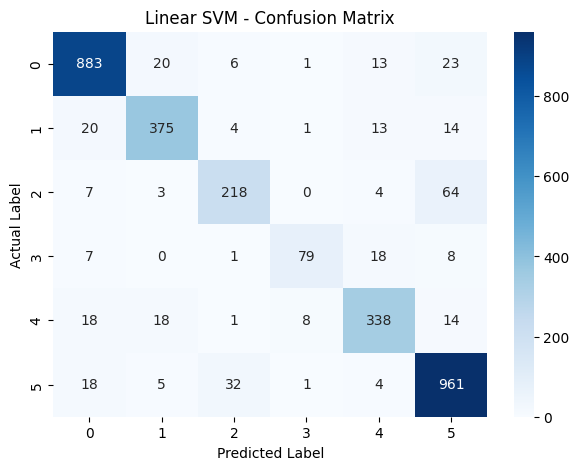

In [ ]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Linear SVM - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Train
rf_model.fit(X_train_tfidf, y_train)

# Prediction
y_pred_rf = rf_model.predict(X_test_tfidf)

# Accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.885625

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       946
           1       0.88      0.86      0.87       427
           2       0.86      0.72      0.78       296
           3       0.83      0.72      0.77       113
           4       0.85      0.87      0.86       397
           5       0.87      0.93      0.90      1021

    accuracy                           0.89      3200
   macro avg       0.87      0.84      0.85      3200
weighted avg       0.89      0.89      0.88      3200



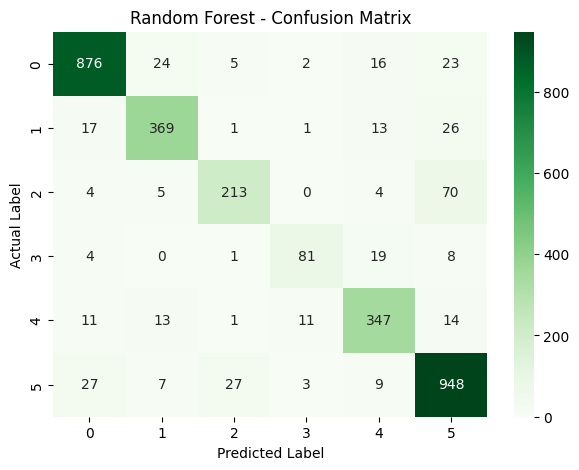

In [ ]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [ ]:
model_names = [
    "Logistic Regression",
    "Linear SVM",
    "Random Forest"
]

accuracies = [
    logistic_accuracy,
    svm_accuracy,
    rf_accuracy
]

for model, acc in zip(model_names, accuracies):
    print(f"{model}: {acc:.4f}")

Logistic Regression: 0.8628
Linear SVM: 0.8919
Random Forest: 0.8856


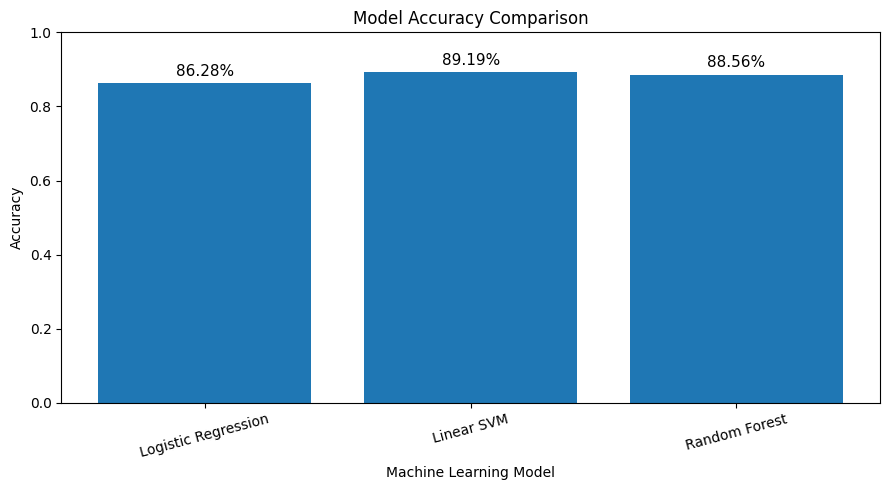

In [ ]:
plt.figure(figsize=(9, 5))

bars = plt.bar(model_names, accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

# Accuracy value উপরে দেখাবে
for bar, acc in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.02,
        f"{acc:.2%}",
        ha="center",
        fontsize=11
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

svm_precision = precision_score(y_test, y_pred_svm, average="weighted")
svm_recall = recall_score(y_test, y_pred_svm, average="weighted")
svm_f1 = f1_score(y_test, y_pred_svm, average="weighted")

rf_precision = precision_score(y_test, y_pred_rf, average="weighted")
rf_recall = recall_score(y_test, y_pred_rf, average="weighted")
rf_f1 = f1_score(y_test, y_pred_rf, average="weighted")

print("Linear SVM")
print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)

print("\nRandom Forest")
print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

Linear SVM
Accuracy : 0.891875
Precision: 0.891110231162864
Recall   : 0.891875
F1 Score : 0.8905866115594726

Random Forest
Accuracy : 0.885625
Precision: 0.8854837839706804
Recall   : 0.885625
F1 Score : 0.884513239288746


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Calculate F1 score for Logistic Regression
logistic_f1 = f1_score(y_test, log_pred, average="weighted")

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Linear SVM",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        svm_accuracy,
        rf_accuracy
    ],
    "F1 Score": [
        logistic_f1,
        svm_f1,
        rf_f1
    ]
})

print(comparison)

                 Model  Accuracy  F1 Score
0  Logistic Regression  0.862812  0.857403
1           Linear SVM  0.891875  0.890587
2        Random Forest  0.885625  0.884513


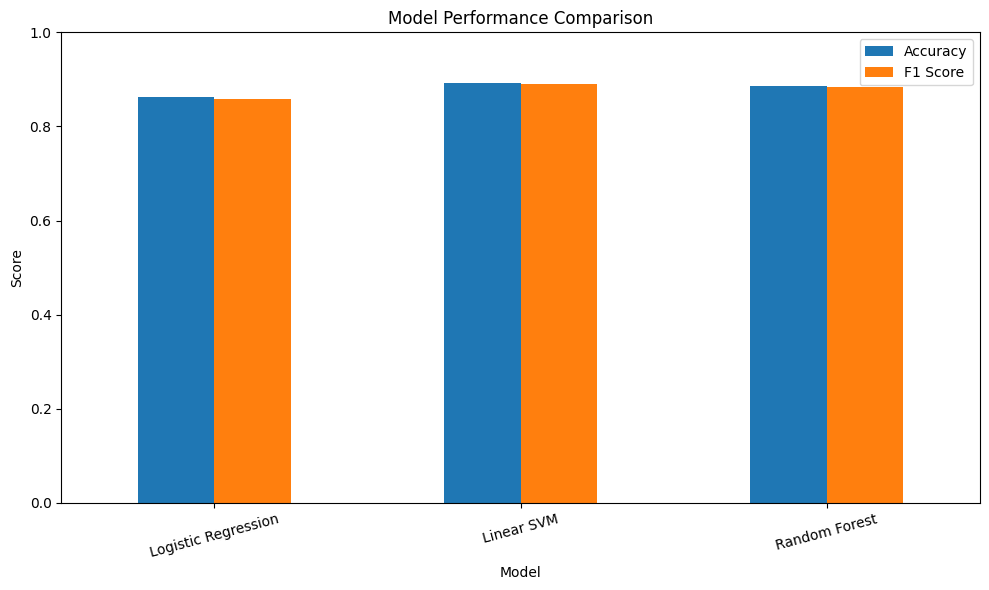

In [ ]:
comparison.plot(
    x="Model",
    y=["Accuracy", "F1 Score"],
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
import joblib
import os

# Save trained models
joblib.dump(logistic_model, "logistic_model.pkl")
joblib.dump(svm_model, "svm_model.pkl")
joblib.dump(rf_model, "random_forest_model.pkl")

# Save the SAME TF-IDF vectorizer used during training
joblib.dump(tfidf_vectorizer, "tfidf_vectorizer.pkl")

print("All models and TF-IDF vectorizer saved successfully!")

All models and TF-IDF vectorizer saved successfully!


In [ ]:
joblib.dump(model, "logistic_model.pkl")

['logistic_model.pkl']

In [ ]:
import streamlit as st
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, f1_score


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="NLP Text Classification",
    page_icon="🧠",
    layout="wide"
)


# ============================================================
# LOAD MODELS AND VECTORIZER
# ============================================================

@st.cache_resource
def load_models():

    logistic_model = joblib.load("logistic_model.pkl")
    svm_model = joblib.load("svm_model.pkl")
    rf_model = joblib.load("random_forest_model.pkl")

    tfidf = joblib.load("tfidf_vectorizer.pkl")

    return logistic_model, svm_model, rf_model, tfidf


try:

    logistic_model, svm_model, rf_model, tfidf = load_models()

except Exception as e:

    st.error("Model files could not be loaded.")

    st.write(
        "Make sure these files are in the same folder as app.py:"
    )

    st.code(
        """
logistic_model.pkl
svm_model.pkl
random_forest_model.pkl
tfidf_vectorizer.pkl
app.py
        """
    )

    st.stop()


# ============================================================
# TITLE
# ============================================================

st.title("🧠 NLP Text Classification System")

st.write(
    "Enter a new text and the trained NLP models will classify it "
    "using the same TF-IDF representation used during training."
)

st.divider()


# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.header("⚙️ Settings")

selected_model = st.sidebar.selectbox(
    "Select Model",
    [
        "Logistic Regression",
        "Linear SVM",
        "Random Forest"
    ]
)

st.sidebar.divider()

st.sidebar.info(
    "The prediction is generated by a machine-learning model "
    "and should not be considered a medical diagnosis."
)


# ============================================================
# MODEL SELECTION
# ============================================================

if selected_model == "Logistic Regression":

    model = logistic_model

elif selected_model == "Linear SVM":

    model = svm_model

else:

    model = rf_model


# ============================================================
# TEXT INPUT
# ============================================================

st.subheader("📝 Enter Your Text")

user_text = st.text_area(
    "Write or paste your text below:",
    height=180,
    placeholder="Example: I have been feeling very sad and tired lately..."
)


# ============================================================
# PREDICTION
# ============================================================

if st.button("🔍 Analyze Text", use_container_width=True):

    if user_text.strip() == "":

        st.warning("Please enter some text first.")

    else:

        # ----------------------------------------------------
        # Convert NEW text using SAME TF-IDF vectorizer
        # ----------------------------------------------------

        text_vector = tfidf.transform([user_text])


        # ----------------------------------------------------
        # Prediction
        # ----------------------------------------------------

        prediction = model.predict(text_vector)[0]


        # ----------------------------------------------------
        # Display prediction
        # ----------------------------------------------------

        st.divider()

        st.subheader("🎯 Prediction")

        st.success(f"Predicted Class: **{prediction}**")


        # ====================================================
        # CONFIDENCE / SCORE
        # ====================================================

        confidence = None

        # Logistic Regression / Random Forest
        if hasattr(model, "predict_proba"):

            probabilities = model.predict_proba(text_vector)[0]

            confidence = np.max(probabilities)

            st.subheader("📊 Prediction Confidence")

            st.progress(float(confidence))

            st.write(
                f"Model confidence score: **{confidence:.2%}**"
            )


            # ------------------------------------------------
            # Class probabilities
            # ------------------------------------------------

            classes = model.classes_

            probability_df = pd.DataFrame({
                "Class": classes,
                "Probability": probabilities
            })

            probability_df["Probability"] = (
                probability_df["Probability"] * 100
            )

            st.write("Class probabilities:")

            st.dataframe(
                probability_df,
                use_container_width=True
            )


        # ====================================================
        # LINEAR SVM
        # ====================================================

        elif hasattr(model, "decision_function"):

            decision_scores = model.decision_function(text_vector)

            if np.ndim(decision_scores) == 1:

                score = float(np.max(np.abs(decision_scores)))

            else:

                score = float(np.max(decision_scores))

            st.subheader("📊 Model Decision Score")

            st.write(
                f"Decision score: **{score:.4f}**"
            )

            st.caption(
                "Linear SVM does not provide a true probability. "
                "This score represents the model's decision strength."
            )


        # ====================================================
        # LOW CONFIDENCE WARNING
        # ====================================================

        if confidence is not None:

            if confidence < 0.60:

                st.warning(
                    "⚠️ The model has relatively low confidence "
                    "for this text. The prediction may be unreliable."
                )

            elif confidence < 0.80:

                st.info(
                    "ℹ️ The model has moderate confidence in this prediction."
                )

            else:

                st.success(
                    "The model has relatively high confidence "
                    "in this prediction."
                )


# ============================================================
# MODEL PERFORMANCE
# ============================================================

st.divider()

st.header("📈 Model Performance")

st.write(
    "Enter the performance values obtained from your test dataset."
)


# ------------------------------------------------------------
# You can replace these values with your actual results
# ------------------------------------------------------------

col1, col2, col3 = st.columns(3)


with col1:

    logistic_accuracy = st.number_input(
        "Logistic Regression Accuracy",
        min_value=0.0,
        max_value=1.0,
        value=0.86,
        step=0.01
    )


with col2:

    svm_accuracy = st.number_input(
        "Linear SVM Accuracy",
        min_value=0.0,
        max_value=1.0,
        value=0.88,
        step=0.01
    )


with col3:

    rf_accuracy = st.number_input(
        "Random Forest Accuracy",
        min_value=0.0,
        max_value=1.0,
        value=0.82,
        step=0.01
    )


# ============================================================
# ACCURACY DATAFRAME
# ============================================================

accuracy_df = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Linear SVM",
        "Random Forest"
    ],

    "Accuracy": [
        logistic_accuracy,
        svm_accuracy,
        rf_accuracy
    ]
})


# ============================================================
# ACCURACY CHART
# ============================================================

st.subheader("📊 Accuracy Comparison")

st.bar_chart(
    accuracy_df.set_index("Model")
)


# ============================================================
# ACCURACY TABLE
# ============================================================

display_accuracy = accuracy_df.copy()

display_accuracy["Accuracy"] = (
    display_accuracy["Accuracy"] * 100
).round(2).astype(str) + "%"

st.dataframe(
    display_accuracy,
    use_container_width=True,
    hide_index=True
)


# ============================================================
# CLASS DISTRIBUTION
# ============================================================

st.divider()

st.header("📊 Dataset Class Distribution")

st.write(
    "You can enter your class counts below to visualize "
    "the distribution of your dataset."
)


# ------------------------------------------------------------
# Number of classes
# ------------------------------------------------------------

num_classes = st.number_input(
    "Number of classes",
    min_value=2,
    max_value=10,
    value=3,
    step=1
)


class_names = []
class_counts = []


for i in range(int(num_classes)):

    col1, col2 = st.columns(2)

    with col1:

        class_name = st.text_input(
            f"Class {i+1} name",
            value=f"Class {i+1}",
            key=f"class_name_{i}"
        )

    with col2:

        class_count = st.number_input(
            f"Class {i+1} samples",
            min_value=0,
            value=100,
            step=10,
            key=f"class_count_{i}"
        )

    class_names.append(class_name)
    class_counts.append(class_count)


distribution_df = pd.DataFrame({

    "Class": class_names,

    "Samples": class_counts

})


# ============================================================
# DISTRIBUTION CHART
# ============================================================

st.subheader("📊 Class Distribution")

st.bar_chart(
    distribution_df.set_index("Class")
)


# ============================================================
# FOOTER
# ============================================================

st.divider()

st.caption(
    "NLP Text Classification Project | "
    "TF-IDF + Machine Learning"
)

2026-09-19 10:31:29.992 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-19 10:31:29.997 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-19 10:31:30.781 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-19 10:31:31.070 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-09-19 10:31:31.074 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-19 10:31:31.078 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-19 10:31:31.082 Thread 'MainThread'

DeltaGenerator()

In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋
changed 22 packages in 2s
⠋
⠋3 packages are looking for funding
⠋  run `npm fund` for details
⠋

In [ ]:
!pip install pyngrok

In [ ]:
!streamlit run app.py --server.address 0.0.0.0 --server.port 8501



2026-09-19 11:04:31.847 Port 8501 is not available


In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run app.py --server.address 0.0.0.0 --server.port 8501 > streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-kkb-use1c0-34vcdpdzynsxv-c.us-east1-0.prod.colab.dev
